In [23]:
# Setup sys.path for notebook imports
from pathlib import Path
import sys

p = Path.cwd()
for _ in range(6):
	if (p / 'backend').exists():
		sys.path.insert(0, str(p))
		break
	p = p.parent
print('PYTHONPATH root:', sys.path[0])

PYTHONPATH root: c:\Users\marce\projetos\quant-terminal


## O que é um RRG (Relative Rotation Graph)

- Um RRG compara vários ativos (por ex., ações do Ibovespa) contra um benchmark (por ex., o próprio índice) e plota cada ativo em um plano 2D.

- **Eixo X:** JdK RS-Ratio — mede a tendência da performance relativa do ativo vs. benchmark.

- **Eixo Y:** JdK RS-Momentum — mede o momentum da performance relativa (basicamente a taxa de variação do RS-Ratio).

- Os eixos se cruzam em 100, criando 4 quadrantes: Leading (x>100, y>100), Weakening (x>100, y<100), Lagging (x<100, y<100) e Improving (x<100, y>100). 

> Observação importante: os detalhes exatos de suavização e normalização do criador (Julius de Kempenaer) são proprietários. Abaixo uso uma aproximação aberta comum na prática: construir RS (ativo/benchmark), normalizar RS em torno de 100 para obter um “RS-Ratio” e definir o “RS-Momentum” como uma razão (ou ROC normalizado) do RS-Ratio — capturando sua inclinação/momentum. 

## Cálculos (aproximação prática e transparente)

1. **Dados:** preços de fechamento (preferencialmente sem ajuste de proventos já incorporado ou use “ajustado” consistentemente) para todos os ativos e o benchmark.

2. **Periodicidade:** RRG é comumente semanal. Se você tiver diário, agregamos para semanal (último preço da semana).

3. **RS (Relative Strength)** de cada ativo i:
$$ RS_𝑖(𝑡) = \frac{{P_𝑖(𝑡)}}{{P_{bench}(𝑡)}} $$
​
4. **RS-Ratio** (centralizado em 100), usando uma média móvel (MA) de 𝑛 períodos para normalizar:
$$ \text{RSRatio}_𝑖(𝑡) = 100 \cdot \frac{{RS_𝑖(𝑡)}}{{\text{MA}_{𝑛}(RS_𝑖(𝑡))}} $$

(Opcional: suavizar com EMA para reduzir ruído.)

5. **RS-Momentum** como momentum do RS-Ratio com janela 𝑚 (normalizado para 100 como linha neutra):
$$ \text{RSMom}_𝑖(𝑡) = 100 \cdot  \frac{{\text{RSRatio}_𝑖(𝑡)}}{{\text{RSRatio}_𝑖(𝑡-m)}} $$
​
(Isso é equivalente a um ROC+100 do RS-Ratio; >100 indica crescimento do RS-Ratio, <100 indica perda de momentum.)

> Esses passos respeitam a lógica: RS-Ratio mede nível/trend relativo; RS-Momentum mede variação desse nível. Cruzamentos e quadrantes seguem o 100 como linha base, como descrito pela documentação pública.

In [24]:
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.signal import savgol_filter

from backend.config import DB_PATH_DAILY_PRICES

TICKERS = ['ZAMP3', 'PETR4', 'VALE3', 'B3SA3']

with sqlite3.connect(DB_PATH_DAILY_PRICES) as conn:
    result = []
    for ticker in TICKERS:
        table = ticker.upper()
        exists = pd.read_sql(
            "SELECT COUNT(1) AS n FROM sqlite_master WHERE type='table' AND name=?;",
            conn,
            params=(table,),
        )['n'].iloc[0] > 0
        if not exists:
            raise ValueError(f"Tabela '{table}' não encontrada no banco.")

        # Lê apenas as colunas 'time' e 'adj_close'
        df = pd.read_sql(
            f"SELECT time, adj_close FROM '{table}' ORDER BY time;",
            conn
        )
        df = df.rename(columns={'adj_close': table})
        result.append(df)

# Faz merge em um único DataFrame (pela coluna 'time')
df_final = result[0]
for df in result[1:]:
    df_final = pd.merge(df_final, df, on='time', how='outer')

# Ordena pelo tempo
df_final = df_final.sort_values('time').reset_index(drop=True).dropna()

print(df_final.head())

            time      ZAMP3     PETR4      VALE3     B3SA3
4529  2017-12-18  17.479376  4.277974  20.464359  5.682678
4530  2017-12-19  17.013922  4.255487  20.469761  5.649143
4531  2017-12-20  17.281311  4.283596  21.172823  5.672358
4532  2017-12-21  17.132759  4.457861  21.486486  5.747163
4533  2017-12-22  17.112953  4.426943  21.748808  5.817998


In [25]:
# ===== Configurações principais =====
date_col = "time"              # mude se necessário; se já estiver no índice, deixe None
benchmark_col = "B3SA3"        # nome da coluna do benchmark
lookback_ratio = 10            # janela p/ normalização do RS (semanas)
lookback_mom = 10              # janela p/ momentum do RS-Ratio (semanas)
tail = 12                      # quantas semanas de "trilha" mostrar
use_ema = True                 # usar EMA (True) ou SMA (False) para suavização do RS


In [26]:
# ===== 1) Ler dados =====
if date_col in df_final.columns :
    df = df_final.copy()
    df[date_col] = pd.to_datetime(df[date_col])
    df.set_index(date_col, inplace=True)
else:
    raise ValueError("Coluna de data especificada não encontrada no DataFrame.")

# Verificações básicas
if benchmark_col not in df.columns:
    raise ValueError(f"Coluna do benchmark '{benchmark_col}' não encontrada no DataFrame.")

assets = [c for c in df.columns if c != benchmark_col]
if len(assets) == 0:
    raise ValueError("Não há ativos além do benchmark nas colunas.")

In [27]:
# ===== 2) Converter para semanal (último preço da semana, por exemplo sexta) =====
weekly = df.resample("W-FRI").last().dropna(how="all")

# Opcional: preencher forward pequenas lacunas de dias sem cotação
weekly = weekly.ffill()

In [28]:
# ===== 3) RS: preço relativo vs benchmark =====
rs = weekly[assets].divide(weekly[benchmark_col], axis=0)

In [29]:
# ===== 4) RS-Ratio: normalização em torno de 100 =====
def ma(x, window, use_ema=True):
    if use_ema:
        return x.ewm(span=window, adjust=False, min_periods=window).mean()
    else:
        return x.rolling(window, min_periods=window).mean()

rs_ma = ma(rs, lookback_ratio, use_ema=use_ema)
rs_ratio = 100.0 * (rs / rs_ma)

In [30]:
# ===== 5) RS-Momentum: ROC normalizado do RS-Ratio =====
rs_ratio_shift = rs_ratio.shift(lookback_mom)
rs_mom = 100.0 * (rs_ratio / rs_ratio_shift)

In [31]:
# ===== EXTRA) Suavizar com Savitzky-Golay (ordem 2, janela 5) =====
rs_ratio = rs_ratio.apply(lambda x: savgol_filter(x.dropna(), 5, 2, mode="interp"), raw=False)
rs_mom   = rs_mom.apply(lambda x: savgol_filter(x.dropna(), 5, 2, mode="interp"), raw=False)

In [32]:
# ===== 6) Selecionar o trecho final para plot (para as trilhas) =====
# usaremos as últimas tail+1 semanas (precisa do ponto anterior para traço)
last_n = tail + 1
rs_ratio_tail = rs_ratio.tail(last_n)
rs_mom_tail = rs_mom.tail(last_n)

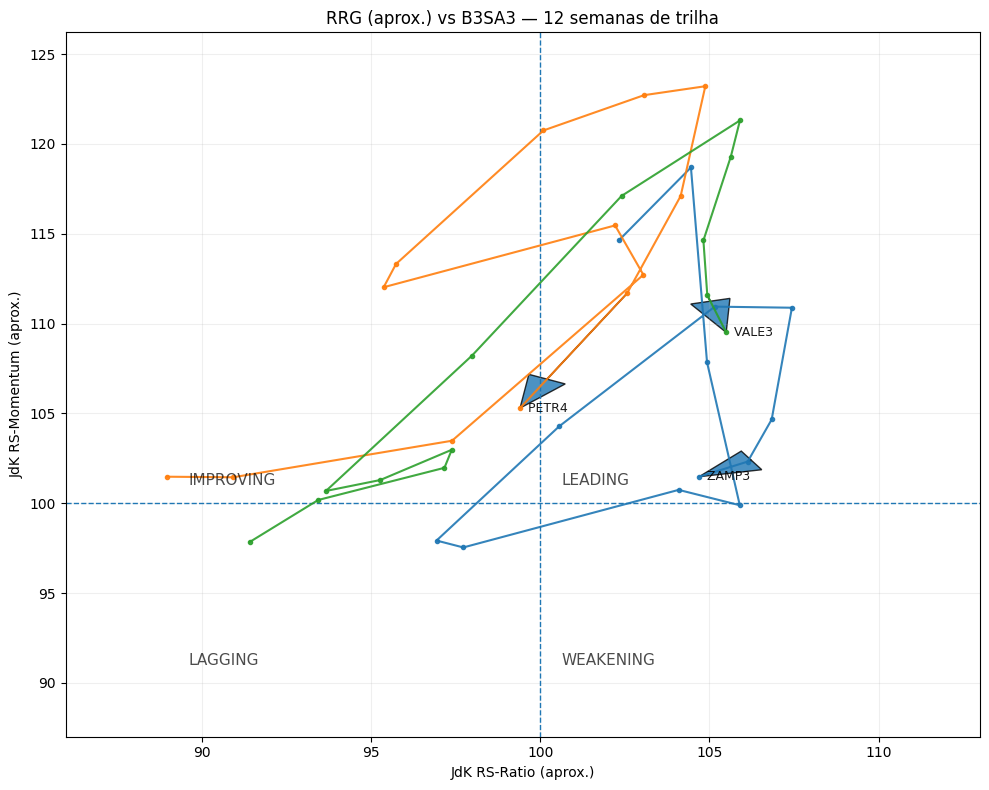

In [33]:
# ===== 7) Plot RRG =====
fig, ax = plt.subplots(figsize=(10, 8))

# Linhas de quadrante
ax.axvline(100, linewidth=1, linestyle="--")
ax.axhline(100, linewidth=1, linestyle="--")

# Rótulos dos quadrantes
xmax = max(110, np.nanmax(rs_ratio_tail.values))
xmin = min(90,  np.nanmin(rs_ratio_tail.values))
ymax = max(110, np.nanmax(rs_mom_tail.values))
ymin = min(90,  np.nanmin(rs_mom_tail.values))

padx = (xmax - xmin) * 0.03
pady = (ymax - ymin) * 0.03

ax.text(100 + padx, 100 + pady, "LEADING", fontsize=11, alpha=0.7)
ax.text(xmin + padx, 100 + pady, "IMPROVING", fontsize=11, alpha=0.7)
ax.text(xmin + padx, ymin + pady, "LAGGING", fontsize=11, alpha=0.7)
ax.text(100 + padx, ymin + pady, "WEAKENING", fontsize=11, alpha=0.7)

# Paleta: deixamos o Matplotlib escolher, mas garantimos uma legenda clara
legend_elements = []

for i, ticker in enumerate(assets):
    x = rs_ratio_tail[ticker].values
    y = rs_mom_tail[ticker].values

    # pular se dados insuficientes
    if np.isnan(x).all() or np.isnan(y).all():
        continue

    # Trajetória (tail)
    ax.plot(x, y, marker="o", linewidth=1.5, markersize=3, alpha=0.9)

    # Seta na direção (último segmento)
    if len(x) >= 2 and not (np.isnan(x[-1]) or np.isnan(y[-1]) or np.isnan(x[-2]) or np.isnan(y[-2])):
        dx = x[-1] - x[-2]
        dy = y[-1] - y[-2]
        ax.arrow(x[-2], y[-2], dx, dy, length_includes_head=True,
                 head_width=1.2, head_length=1.8, alpha=0.8)

    # Rótulo no último ponto
    if not (np.isnan(x[-1]) or np.isnan(y[-1])):
        ax.text(x[-1], y[-1], f"  {ticker}", fontsize=9, va="center", alpha=0.9)

    legend_elements.append(Line2D([0], [0], marker='o', linestyle='-',
                                  label=ticker, markersize=5))

# Ajustes de eixos
ax.set_xlabel("JdK RS-Ratio (aprox.)")
ax.set_ylabel("JdK RS-Momentum (aprox.)")
ax.set_title(f"RRG (aprox.) vs {benchmark_col} — {tail} semanas de trilha")

# Margens e limites
ax.set_xlim(xmin - 3, xmax + 3)
ax.set_ylim(ymin - 3, ymax + 3)

# Grid leve
ax.grid(True, alpha=0.2)

plt.tight_layout()
plt.show()

In [34]:
# ===== 8) DataFrame final com valores atuais (útil para tabela/inspeção) =====
current = pd.DataFrame({
    "Date": weekly.index[-1],
    "RS-Ratio": rs_ratio.iloc[-1],
    "RS-Momentum": rs_mom.iloc[-1]
}).loc[assets].sort_values(["RS-Ratio", "RS-Momentum"], ascending=False)

# Função para classificar quadrante
def classify_quadrant(row):
    if row["RS-Ratio"] >= 100 and row["RS-Momentum"] >= 100:
        return "Leading"
    elif row["RS-Ratio"] < 100 and row["RS-Momentum"] >= 100:
        return "Improving"
    elif row["RS-Ratio"] < 100 and row["RS-Momentum"] < 100:
        return "Lagging"
    else:
        return "Weakening"

current["Quadrant"] = current.apply(classify_quadrant, axis=1)

print("\nValores atuais (última semana):")
print(current.round(2))


Valores atuais (última semana):
            Date  RS-Ratio  RS-Momentum   Quadrant
VALE3 2025-08-15    105.50       109.50    Leading
ZAMP3 2025-08-15    104.69       101.47    Leading
PETR4 2025-08-15     99.40       105.29  Improving
